<a href="https://colab.research.google.com/github/Giomora-IA/IA--NOTA-AND-EJERCICIOS/blob/main/Red_Neuronal_PP4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importación de Librerías


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


# Carga y Exploración del Dataset

In [13]:
# Cargar el archivo de respuestas de la encuesta
excel_path = "Formulario sin título (Respuestas).xlsx"
df = pd.read_excel(excel_path, sheet_name='Respuestas de formulario 1')

print(f"Dimensiones originales del dataset: {df.shape}")
print("Columnas disponibles:")
for col in df.columns:
    print("-", col)

Dimensiones originales del dataset: (31, 27)
Columnas disponibles:
- Marca temporal
- ¿Aceptas participar voluntariamente?
- Carrera / Licenciatura:
- Semestre que cursas:
- Edad o Rango de edad (Opcional):
- ¿Utilizas habitualmente herramientas de Inteligencia Artificial generativa (ChatGPT, Claude, Gemini, Copilot, DeepSeek, etc.)?
- ¿Qué herramientas de IA utilizas con mayor frecuencia? (Puedes elegir varias)
- ¿Pagas alguna suscripción a un servicio de IA?
- ¿Cuánto pagas en suscriptores de IA?
- ¿Cuantos días a la semana ocupas herramientas de IA?
- En los días que utilizas IA, ¿cuántos mensajes o instrucciones (prompts) en total envías al día? (Recuerda que un chat puede tener varios prompts o reintentos)
- ¿Cómo describirías la longitud promedio de los textos o instrucciones que le envías a la IA?
- ¿Qué tan largas suelen ser las respuestas que normalmente recibes por parte de la IA?
- ¿Generas contenidos multimedia (imágenes, audio o video) con IA?
- Cuando la IA te da una resp

# Preprocesamiento y Mapeo de Variables

In [14]:
# Diccionarios de mapeo para convertir texto a valores numéricos ordinales
freq_uso_map = {
    '1 a 2 días': 1,
    '3 a 4 días': 2,
    'Todos los días': 3
}

prompts_map = {
    'Menos de 5': 1,
    'De 5 a 15': 2,
    'De 16 a 30': 3,
    'Más de 30': 4
}

reintentos_map = {
    'Rara vez reintento (1 sola vez y cambio de tema o lo busco en Google)': 1,
    '2 a 3 veces refino la pregunta': 2,
    '4 a 6 veces sigo ajustando el prompt hasta obtener lo que quiero': 3,
    'Más de 6 reintentos continuos en la misma consulta': 4
}

sin_cambio_map = {
    'Nunca': 1,
    'A veces': 2,
    'Frecuentemente': 3,
    'Siempre': 4
}

capacitacion_map = {
    'No': 0,
    'Si, por cuenta propia': 1,
    'Si, impartido por la universidad': 2
}

# Crear DataFrame limpio con las entradas solicitadas
clean_df = pd.DataFrame()
clean_df['Frecuencia_Uso'] = df['¿Cuantos días a la semana ocupas herramientas de IA?'].map(freq_uso_map)
clean_df['Cantidad_Prompts'] = df['En los días que utilizas IA, ¿cuántos mensajes o instrucciones (prompts) en total envías al día? (Recuerda que un chat puede tener varios prompts o reintentos)'].map(prompts_map)
clean_df['Reintentos'] = df['Cuando la IA te da una respuesta incompleta o incorrecta, ¿cuántas veces sueles reintentar/reformular el mismo prompt en esa misma sesión?'].map(reintentos_map)
clean_df['Trabajo_Sin_Cambio'] = df['¿Con qué frecuencia entregas un trabajo o tarea académica con la respuesta de la IA sin realizar cambios significativos?'].map(sin_cambio_map)
clean_df['Capacitacion_Previa'] = df['¿Has recibido previamente algún curso, taller o capacitación sobre el uso correcto de la IA?'].map(capacitacion_map)

# Función para calcular complejidad de necesidades según cantidad de opciones seleccionadas
def score_necesidad(text):
    if pd.isna(text):
        return 1
    return text.count(',') + 1

clean_df['Necesidad_Complejidad'] = df['¿Para qué necesidades específicas utilizas la IA principalmente?'].apply(score_necesidad)

# Limpiar valores faltantes si los hay
clean_df = clean_df.fillna(1)
print(clean_df.head())

   Frecuencia_Uso  Cantidad_Prompts  Reintentos  Trabajo_Sin_Cambio  \
0               2                 4           4                   2   
1               3                 3           2                   2   
2               1                 2           3                   2   
3               1                 1           2                   1   
4               2                 2           1                   1   

   Capacitacion_Previa  Necesidad_Complejidad  
0                    0                      1  
1                    0                      5  
2                    1                      3  
3                    1                      4  
4                    0                      1  


# Generación de la variable

In [15]:
def asignar_perfil(row):
    # Rúbrica ponderada para clasificar al usuario en perfiles 0, 1 o 2
    score = (
        row['Frecuencia_Uso'] * 1.5 +
        row['Cantidad_Prompts'] * 2.0 +
        row['Reintentos'] * 1.5 +
        row['Capacitacion_Previa'] * 2.0 +
        row['Necesidad_Complejidad'] * 1.0 -
        row['Trabajo_Sin_Cambio'] * 1.0
    )
    if score <= 7:
        return 0  # Perfil 0: Básico / Pasivo
    elif score <= 12:
        return 1  # Perfil 1: Intermedio / Colaborativo
    else:
        return 2  # Perfil 2: Avanzado / Técnico / Crítico

clean_df['Perfil_Observado'] = clean_df.apply(asignar_perfil, axis=1)

print("Distribución de los Perfiles de Uso:")
print(clean_df['Perfil_Observado'].value_counts())

Distribución de los Perfiles de Uso:
Perfil_Observado
1    11
2    10
0    10
Name: count, dtype: int64


# División de Datos y Normalización (Train/Test)

In [16]:
# Definir Características (X) y Etiquetas (y)
X = clean_df[['Frecuencia_Uso', 'Cantidad_Prompts', 'Reintentos', 'Trabajo_Sin_Cambio', 'Capacitacion_Previa', 'Necesidad_Complejidad']].values
y = clean_df['Perfil_Observado'].values

# Partición 80% entrenamiento, 20% prueba (con estratificación para mantener proporciones)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Escalado de características (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dimensiones X_train:", X_train_scaled.shape)
print("Dimensiones X_test:", X_test_scaled.shape)

Dimensiones X_train: (24, 6)
Dimensiones X_test: (7, 6)


# Construcción de la Red Neuronal Multicapa (MLP)

In [17]:
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu', name='Capa_Oculta_1'),
    layers.Dense(8, activation='relu', name='Capa_Oculta_2'),
    layers.Dense(3, activation='softmax', name='Capa_Salida') # 3 clases (Perfiles 0, 1, 2)
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_Oculta_1 (Dense)           │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Oculta_2 (Dense)           │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Salida (Dense)             │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 275 (1.07 KB)

 Trainable params: 275 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

# Entrenamiento



In [18]:
EPOCHS = 60
BATCH_SIZE = 4

history = model.fit(
    X_train_scaled, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test_scaled, y_test),
    verbose=1
)

Epoch 1/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.2083 - loss: 1.3242 - val_accuracy: 0.1429 - val_loss: 1.4581
Epoch 2/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2083 - loss: 1.2786 - val_accuracy: 0.1429 - val_loss: 1.4297
Epoch 3/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2083 - loss: 1.2420 - val_accuracy: 0.1429 - val_loss: 1.3979
Epoch 4/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2500 - loss: 1.2089 - val_accuracy: 0.1429 - val_loss: 1.3693
Epoch 5/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.2500 - loss: 1.1735 - val_accuracy: 0.1429 - val_loss: 1.3450
Epoch 6/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2500 - loss: 1.1444 - val_accuracy: 0.1429 - val_loss: 1.3197
Epoch 7/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2917 - loss: 1.1122 - val_accuracy: 0.1429 - val_loss: 1.2966
Epoch 8/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2917 - loss: 1.0839 - val_accuracy: 0.1429 - val_loss: 1.2760


# Evaluación, Gráficas de Rendimiento y Métricas


--- Resultados Finales ---
Pérdida en Test: 0.7821
Precisión (Accuracy) en Test: 57.14%


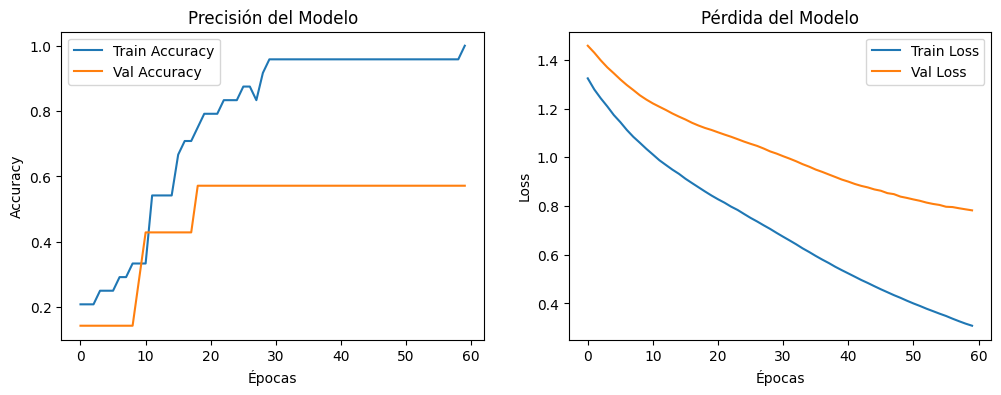

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.40      1.00      0.57         2
           1       0.00      0.00      0.00         3
           2       1.00      1.00      1.00         2

    accuracy                           0.57         7
   macro avg       0.47      0.67      0.52         7
weighted avg       0.40      0.57      0.45         7



In [19]:
# Evaluar pérdida y precisión
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"\n--- Resultados Finales ---")
print(f"Pérdida en Test: {test_loss:.4f}")
print(f"Precisión (Accuracy) en Test: {test_acc * 100:.2f}%")

# Gráficas de entrenamiento (Loss y Accuracy)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Precisión del Modelo')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Pérdida del Modelo')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Reporte de clasificación y matriz de confusión
y_pred_probs = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))